## K-Means Clustering of RL² Hidden States on Evenly Spaced Action Offset Tasks

This notebook creates the reference hidden states that the other K-Means notebooks in this folder use.

In HalfCheetah, the task parameter is an action offset `a_m` between −0.2 and +0.2 that is added to every action of the agent.

1. **Evenly spaced tasks:** action offsets evenly spaced between −0.2 and +0.2 are created with `sample_tasks_eval`.
2. **Rollout:** the trained RL2 agent plays every task for `steps_per_env` steps with a fixed seed, so the reference run is reproducible. The GRU hidden state of each task is averaged over all steps.
3. **Clustering:** K-Means groups the average hidden states into the k selected in `kmeans_k_selection.ipynb`, with the same settings as in the other notebooks.

**Note:** for HalfCheetah, no k reaches the prediction strength threshold in `kmeans_k_selection.ipynb`, so there is no reproducible cluster structure (k = 1). To compare with the other systems, k = 2 is used here, whose mean prediction strength is just below the threshold. The results for k = 2 are for comparison only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import joblib

from sklearn.decomposition import PCA

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import CLUSTER_COLORS, fit_kmeans, sort_clusters_by_task_parameter

system = SYSTEMS["halfcheetah"]

In [2]:
# Generate 20 evenly spaced action offset tasks between -0.2 and +0.2
env_configs = system.sample_tasks_eval(num_envs=20)

# Create 20 parallel HalfCheetah environments based on these configurations
envs = system.make_envs(env_configs)

In [3]:
# Create the RL2 actor-critic model and load the trained weights
model = load_model(system)

In [4]:
steps_per_env = 3000

reference_seed = 42

# Play every task for steps_per_env steps and average its GRU hidden state over all steps
try:
    avg_hidden_states = collect_avg_hidden_states(
        model, system, envs, seed=reference_seed, steps=steps_per_env
    )
finally:
    envs.close()

In [5]:
# Save the 256 dim average hidden states of the evenly spaced tasks
np.save(CHECKPOINT_DIR / "halfcheetah_action_avg_hidden_states.npy", avg_hidden_states)

print(avg_hidden_states.shape)

(20, 256)


In [6]:
# Number of clusters selected with the prediction strength in kmeans_k_selection.ipynb
best_k = int(np.load(CHECKPOINT_DIR / "halfcheetah_action_kmeans_k_selection.npz")["best_k"])

# No k reaches the threshold for HalfCheetah (k = 1, no reproducible cluster structure).
# k = 2 is used for comparison only, its mean prediction strength is just below the threshold.
selected_k = best_k
if selected_k == 1:
    best_k = 2
comparison_note = ", below threshold, for comparison only" if selected_k == 1 else ""

kmeans = fit_kmeans(avg_hidden_states, best_k)
cluster_assignments = kmeans.labels_

np.save(CHECKPOINT_DIR / "halfcheetah_action_cluster_labels.npy", cluster_assignments)
joblib.dump(kmeans, CHECKPOINT_DIR / "halfcheetah_action_kmeans.joblib")

print(cluster_assignments)

[1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]


In [7]:
# Display the offset and assigned cluster for each environment
for i, cfg in enumerate(env_configs):
    print(f"Environment {i}: Action offset = {cfg['a_m']:.3f}, Cluster = {cluster_assignments[i]}")

Environment 0: Action offset = -0.200, Cluster = 1
Environment 1: Action offset = -0.179, Cluster = 1
Environment 2: Action offset = -0.158, Cluster = 1
Environment 3: Action offset = -0.137, Cluster = 1
Environment 4: Action offset = -0.116, Cluster = 1
Environment 5: Action offset = -0.095, Cluster = 1
Environment 6: Action offset = -0.074, Cluster = 1
Environment 7: Action offset = -0.053, Cluster = 1
Environment 8: Action offset = -0.032, Cluster = 0
Environment 9: Action offset = -0.011, Cluster = 0
Environment 10: Action offset = 0.011, Cluster = 0
Environment 11: Action offset = 0.032, Cluster = 0
Environment 12: Action offset = 0.053, Cluster = 0
Environment 13: Action offset = 0.074, Cluster = 0
Environment 14: Action offset = 0.095, Cluster = 0
Environment 15: Action offset = 0.116, Cluster = 0
Environment 16: Action offset = 0.137, Cluster = 0
Environment 17: Action offset = 0.158, Cluster = 0
Environment 18: Action offset = 0.179, Cluster = 0
Environment 19: Action offset =

In [8]:
# Reduce the 256 dim average hidden states to 2 dim using PCA
pca = PCA(n_components=2)
reduced_h = pca.fit_transform(avg_hidden_states)

# Save the fitted PCA model
joblib.dump(pca, CHECKPOINT_DIR / "halfcheetah_action_pca.joblib")

['C:\\Users\\graph\\OneDrive\\Dokumente\\Uni Wien WS26\\Bachelor Arbeit\\RL2-Torch-Pattern-Recognition\\checkpoints\\halfcheetah_action_pca.joblib']

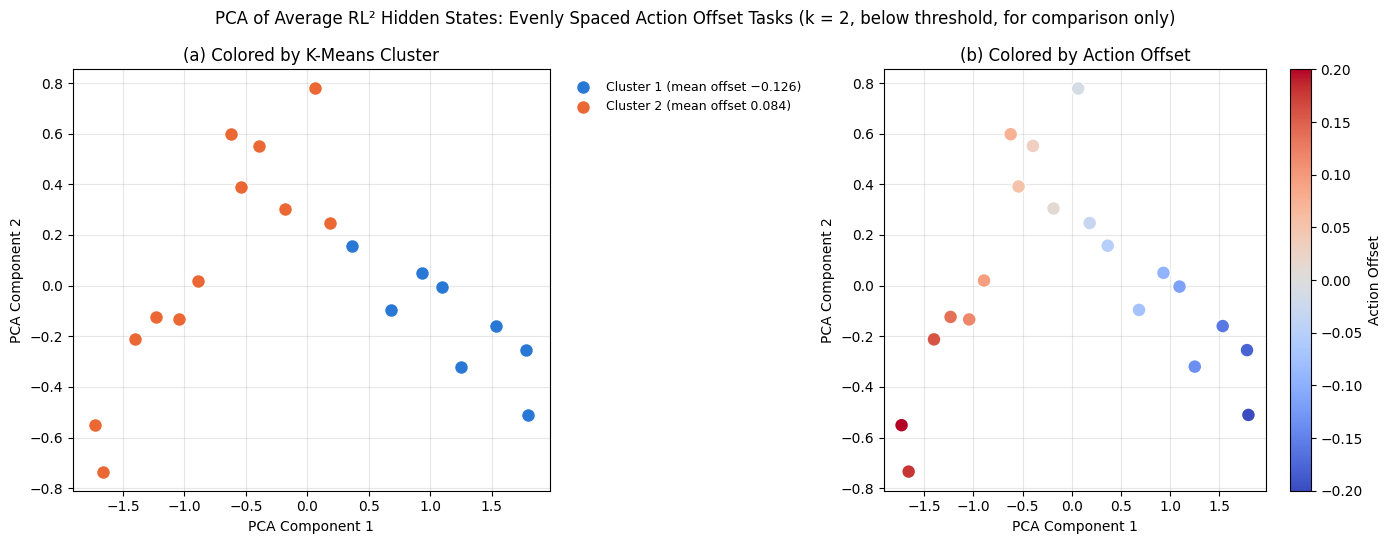

In [9]:
# Extract the action offset of each task
reference_offset_values = task_parameters(system, env_configs)

# Cluster colors and numbering from kmeans_utils.py, the same in all notebooks

num_clusters = kmeans.n_clusters
assert num_clusters <= len(CLUSTER_COLORS), "Add more cluster colors for this number of clusters"

# Mean offset of every cluster, clusters numbered by it (1 = most negative offset)
cluster_offset_means, cluster_order, cluster_number = sort_clusters_by_task_parameter(
    kmeans.labels_, reference_offset_values, num_clusters
)

plot_name = "halfcheetah_kmeans_pca_reference.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Hidden states colored by their K-Means cluster, one scatter per cluster for the legend
for cluster in cluster_order:
    number = cluster_number[cluster]
    in_cluster = cluster_assignments == cluster
    axes[0].scatter(
        reduced_h[in_cluster, 0],
        reduced_h[in_cluster, 1],
        color=CLUSTER_COLORS[number - 1],
        s=100, edgecolors="white", linewidths=1,
        label=f"Cluster {number} (mean offset {cluster_offset_means[cluster]:.3f})".replace("-", "−")
    )
axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
axes[0].set_title("(a) Colored by K-Means Cluster")

# (b) Hidden states colored by their action offset
# Fixed color range (-0.2 to +0.2), so all offset plots use the same scale
scatter = axes[1].scatter(
    reduced_h[:, 0],
    reduced_h[:, 1],
    c=reference_offset_values,
    cmap="coolwarm",
    vmin=-0.2, vmax=0.2,
    s=100, edgecolors="white", linewidths=1
)
fig.colorbar(scatter, ax=axes[1], label="Action Offset")
axes[1].set_title("(b) Colored by Action Offset")

for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(f"PCA of Average RL² Hidden States: Evenly Spaced Action Offset Tasks (k = {best_k}{comparison_note})")
fig.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()